## MODULE A


In [1]:
import ultralytics
import cv2
import matplotlib.pyplot as plt
print(f"Ultralytics version: {ultralytics.__version__}")
print(f"OpenCV version: {cv2.__version__}")


Creating new Ultralytics Settings v0.0.8 file  
View Ultralytics Settings with 'yolo settings' or at 'C:\Users\User\AppData\Roaming\Ultralytics\settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart#ultralytics-settings.
Ultralytics version: 8.4.138
OpenCV version: 5.0.0


**Task A.1 — Classification vs Detection vs Segmentation (15 min)** 

Ask ChatGPT: "Explain the difference between image classification, object detection, and instance segmentation with visual examples."
Research: What are the outputs of each task? (e.g., classification → class label only)

- Image Classification answers the question, "What is the main subject of this image?" It assigns a single categorical label to the entire image without providing any location data.

    Output: Class label only.

    Visual Example: You input a photograph of a golden retriever playing in a park. The model outputs a single text label: Dog.

- Object Detection answers the question, "What objects are in this image, and where are they located?" It identifies multiple objects within the same image and draws rectangular boundaries around them.

    Output: Class label + Bounding box coordinates (typically x, y, width, height).

    Visual Example: You input a photograph of a street. The model draws a red rectangle around a car labeled Car, a blue rectangle around a pedestrian labeled Person, and a green rectangle around a bicycle labeled Bicycle.

- Instance Segmentation answers the question, "What exact pixels belong to which specific object?" It goes a step further than bounding boxes by outlining the exact shape of every individual object, distinguishing between different objects of the same class.

    Output: Class label + Pixel mask (a map detailing the exact pixels making up the object).

    Visual Example: You input a photograph of two cars parked next to each other. Instead of drawing boxes, the model colors the exact silhouette of the first car in yellow and the exact silhouette of the second car in purple. It knows exactly where the curves of the tires and mirrors are, and it knows they are two distinct instances of the class Car.

Fill in:


### Task A.1 - Classification vs Detection vs Segmentation

| Task | Output | Example | Real-world Application | Source |
| --- | --- | --- | --- | --- |
| **Classification** | Class label only | "This is a cat" | Identifying if a medical X-ray shows a tumor or is healthy. | https://docs.ultralytics.com/tasks/classify/ |
| **Object Detection** | Class label + Bounding box coordinates | Bounding box around cat | Pedestrian and vehicle detection for autonomous driving systems. | https://www.geeksforgeeks.org/object-detection-vs-object-recognition-vs-image-segmentation/ |
| **Instance Segmentation** | Class label + Pixel mask | Pixel mask of cat | Medical imaging to extract the exact boundaries of individual cells. | https://docs.ultralytics.com/tasks/segment/ |




**Task A.2 — Object Detection Fundamentals (15 min)**

1. Ask ChatGPT: "What is Intersection over Union (IoU)? Draw a diagram and explain."

    Intersection over Union (IoU) is an evaluation metric used to measure the accuracy of an object detector on a particular dataset. It measures how much the bounding box predicted by the model overlaps with the actual, correct bounding box (the "ground truth").

    IoU is calculated by dividing the Area of Overlap (intersection) by the Area of Union (the total space covered by both boxes combined).

    Refer code below for IoU Diagram 

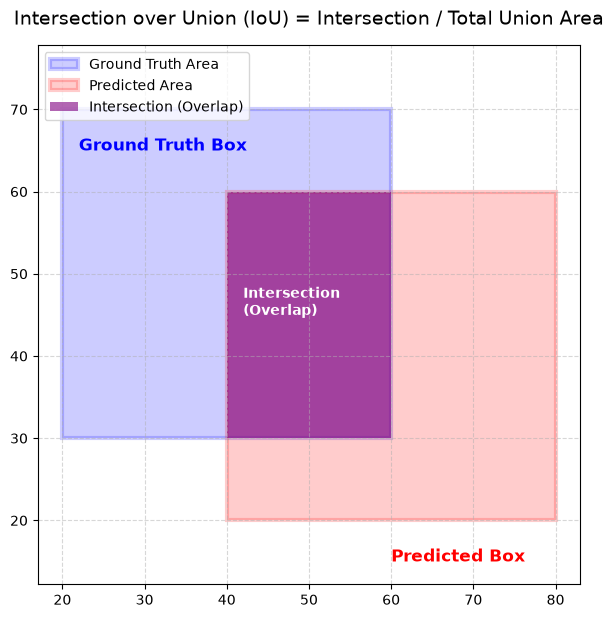

In [2]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

fig, ax = plt.subplots(figsize=(7, 7))

# Ground Truth Box (Blue)
gt_box = patches.Rectangle((20, 30), 40, 40, linewidth=3, edgecolor='blue', facecolor='blue', alpha=0.2, label='Ground Truth Area')
ax.add_patch(gt_box)

# Predicted Box (Red)
pred_box = patches.Rectangle((40, 20), 40, 40, linewidth=3, edgecolor='red', facecolor='red', alpha=0.2, label='Predicted Area')
ax.add_patch(pred_box)

# Intersection (Purple Overlap)
intersection = patches.Rectangle((40, 30), 20, 30, linewidth=0, facecolor='purple', alpha=0.6, label='Intersection (Overlap)')
ax.add_patch(intersection)

# Annotations
plt.text(22, 65, 'Ground Truth Box', color='blue', fontsize=12, fontweight='bold')
plt.text(60, 15, 'Predicted Box', color='red', fontsize=12, fontweight='bold')
plt.text(42, 45, 'Intersection\n(Overlap)', color='white', fontsize=10, fontweight='bold')

# Configure Plot
plt.xlim(0, 100)
plt.ylim(0, 100)
plt.title('Intersection over Union (IoU) = Intersection / Total Union Area', fontsize=14, pad=15)
plt.legend(loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.axis('equal')
plt.show()

2. Ask ChatGPT: "What is Non-Maximum Suppression (NMS)? Why do we need it in object detection?"

    Non-Maximum Suppression (NMS) is a post-processing algorithm used to filter out duplicate bounding box predictions so that each object is only detected once.

    Why we need it:
In object detection models like YOLO, the image is divided into a grid, and multiple grid cells might detect the same object. Because of this, the model often outputs a cluster of slightly different bounding boxes around a single object (e.g., predicting 5 different boxes around one cat). Without NMS, your final output would be a messy jumble of overlapping boxes for a single item.

How it works:

- Sort: The algorithm looks at all predicted boxes for a specific class and sorts them by their confidence score (how certain the model is that the object is there).

- Select: It selects the bounding box with the highest confidence score and keeps it as a final prediction.

- Suppress: It compares this chosen box with all other overlapping boxes. If another box overlaps with the chosen box by too much (i.e., its IoU is above a certain threshold, like 0.45), the algorithm assumes they are detecting the exact same object and deletes (suppresses) the lower-confidence box.

- Repeat: It moves to the next highest confidence box that wasn't deleted and repeats the process until only distinct boxes remain.


Fill in:

| Concept | Definition | Formula (if applicable) | Why It's Needed | Source |
| --- | --- | --- | --- | --- |
| **IoU** | Intersection over Union; ratio of the overlapping area between the predicted box and the ground truth to their combined area. | $\frac{\text{Area of Overlap}}{\text{Area of Union}}$ | Evaluates how accurately the bounding box localizes the object. | https://pyimagesearch.com/2016/11/07/intersection-over-union-iou-for-object-detection/ |
| **Precision** | Proportion of positive identifications that are actually correct. | $TP / (TP + FP)$ | Minimizes false positives (e.g., detecting a non-existent object). |https://developers.google.com/machine-learning/crash-course/classification/precision-and-recall |
| **Recall** | Proportion of actual positive objects that were correctly identified. | $TP / (TP + FN)$ | Minimizes false negatives (e.g., missing an actual object in the image). | https://developers.google.com/machine-learning/crash-course/classification/precision-and-recall |
| **mAP (mean Average Precision)** | The mean of the Average Precision (AP) scores across all classes at various IoU thresholds. | $\frac{1}{N} \sum_{i=1}^{N} AP_i$ | Standard metric to compare overall model accuracy across different object classes. | https://blog.roboflow.com/mean-average-precision/ |
| **NMS** | Non-Maximum Suppression; an algorithm that filters out overlapping bounding boxes based on confidence scores. | Keep highest confidence box, discard others with $IoU > \text{threshold}$. | Prevents the model from outputting multiple bounding boxes for a single object. | https://www.geeksforgeeks.org/non-maximum-suppression-nms/ |


**Task A.3 — YOLO Architecture (15 min)**

1. Ask ChatGPT: "Explain the YOLO architecture. What makes it different from two-stage detectors like Faster R-CNN?"

    YOLO (You Only Look Once) frames object detection as a single regression problem. It takes an image, divides it into an $S \times S$ grid, and simultaneously predicts bounding boxes, confidence scores, and class probabilities for each grid cell in a single forward pass through the neural network.

    This makes it drastically different from two-stage detectors like Faster R-CNN. Faster R-CNN uses a two-step process: first, it uses a Region Proposal Network (RPN) to generate thousands of potential bounding boxes (regions of interest). Second, it passes each of those individual proposals through a classifier to determine what object is inside and refine the box dimensions. Because YOLO skips the regional proposal step and processes the entire image at once, it is significantly faster, though historically slightly less accurate on tiny objects compared to two-stage models.

2. Ask ChatGPT: "What are anchor boxes in YOLO? How do they help with bounding box prediction?"

    Anchor boxes are predefined, fixed-size bounding boxes of various aspect ratios (e.g., tall and skinny for a person, short and wide for a car) established before training begins.

    Instead of forcing the neural network to predict the exact width and height of an object entirely from scratch (which is mathematically unstable and hard to learn), YOLO predicts offsets or adjustments to these predefined anchor boxes. By starting with a shape that is already close to the object's real shape, the model learns to localize objects much faster and more accurately.


**Prompt 1: "Explain the YOLO architecture. What makes it different from two-stage detectors like Faster R-CNN?"**

**Answer:**
YOLO (You Only Look Once) frames object detection as a single regression problem. It takes an image, divides it into an $S \times S$ grid, and simultaneously predicts bounding boxes, confidence scores, and class probabilities for each grid cell in a single forward pass through the neural network.

This makes it drastically different from two-stage detectors like Faster R-CNN. Faster R-CNN uses a two-step process: first, it uses a Region Proposal Network (RPN) to generate thousands of potential bounding boxes (regions of interest). Second, it passes each of those individual proposals through a classifier to determine what object is inside and refine the box dimensions. Because YOLO skips the regional proposal step and processes the entire image at once, it is significantly faster, though historically slightly less accurate on tiny objects compared to two-stage models.

**Prompt 2: "What are anchor boxes in YOLO? How do they help with bounding box prediction?"**

**Answer:**
Anchor boxes are predefined, fixed-size bounding boxes of various aspect ratios (e.g., tall and skinny for a person, short and wide for a car) established before training begins.

Instead of forcing the neural network to predict the exact width and height of an object entirely from scratch (which is mathematically unstable and hard to learn), YOLO predicts **offsets** or **adjustments** to these predefined anchor boxes. By starting with a shape that is already close to the object's real shape, the model learns to localize objects much faster and more accurately.


| Feature | YOLO (One-Stage) | Faster R-CNN (Two-Stage) | Source |
| --- | --- | --- | --- |
| **Number of stages** | 1 (Predicts classes and boxes simultaneously over a grid). | 2 (Generates region proposals first, then classifies and refines). | https://www.geeksforgeeks.org/yolo-you-only-look-once-real-time-object-detection/ |
| **Speed** | Extremely fast; designed for real-time inference (often 45-155+ FPS). | Slower; bottlenecked by the processing of thousands of region proposals. | https://arxiv.org/abs/1506.02640 |
| **Accuracy** | Good, but historically can struggle with small, clustered objects. | Very high accuracy; excels at detecting small objects and crowded scenes. | https://www.geeksforgeeks.org/faster-r-cnn-ml/|
| **Typical use case** | Real-time video analytics, autonomous driving, robotics, edge computing. | Medical image analysis, satellite imagery, tasks where precision outweighs speed. |https://pyimagesearch.com/2018/11/12/yolo-object-detection-with-opencv/ |
| **Key innovation** | Unifies the detection pipeline into a single neural network treating detection as a regression problem. | Introduces the Region Proposal Network (RPN) to share convolutional features with the detection network. | https://arxiv.org/abs/1506.01497 |

## MODULE B

In [6]:
from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt
# Load a pre-trained YOLOv8n model (n = nano version, smallest/fastest)
model = YOLO('yolov8n.pt')
# Print model information
print(f"Model loaded successfully!")
print(f"Number of classes: {len(model.names)}")
print(f"Class names: {list(model.names.values())[:10]}...")  # First 10 classes

Model loaded successfully!
Number of classes: 80
Class names: ['person', 'bicycle', 'car', 'motorcycle', 'airplane', 'bus', 'train', 'truck', 'boat', 'traffic light']...


1. Research: Ask ChatGPT: "What do the different YOLO variants mean? (yolov8n, yolov8s, yolov8m, yolov8l, yolov8x)"

    The letters at the end of the YOLOv8 model names refer to the model's size and complexity. As you move from n to x, the neural network becomes deeper (more layers) and wider (more channels). This creates a direct trade-off: larger models achieve higher accuracy (mAP) because they can learn more complex features, but they require significantly more computational power and run at slower speeds (lower FPS).

- n (nano): The smallest and fastest model. It sacrifices some accuracy for extreme speed, making it perfect for mobile phones or low-power edge devices (like a Raspberry Pi).

- s (small): A step up in size, offering a good balance of speed and accuracy for standard computers without high-end GPUs.

- m (medium): The middle ground. It provides high accuracy while still maintaining real-time performance on systems with a dedicated GPU.

- l (large): A heavy model designed for high precision. It is slower and usually requires powerful cloud servers or high-end desktop GPUs to run effectively.

- x (extra large): The most massive and accurate model in the family. It is typically used for research, highly complex datasets, or tasks where accuracy is far more important than real-time speed.

Fill in:

| Model Variant | Size | Speed | Accuracy | Best For | Source |
| --- | --- | --- | --- | --- | --- |
| **YOLOv8n (nano)** | Smallest (~3.2M params) | Fastest | Lowest (relative) | Edge devices, mobile applications, strict real-time needs on CPUs. | https://docs.ultralytics.com/models/yolov8/|
| **YOLOv8s (small)** | Small (~11.2M params) | Fast | Good | Balanced real-time video processing on standard hardware. | https://docs.ultralytics.com/models/yolov8/ |
| **YOLOv8m (medium)** | Medium (~25.9M params) | Moderate | High | Desktop GPU processing, general-purpose detection. | https://docs.ultralytics.com/models/yolov8/ |
| **YOLOv8l (large)** | Large (~43.7M params) | Slow | Very High | Cloud computing, scenarios requiring high precision. | https://docs.ultralytics.com/models/yolov8/|
| **YOLOv8x (extra large)** | Largest (~68.2M params) | Slowest | Highest | Research, complex datasets, high-end GPU servers. | https://docs.ultralytics.com/models/yolov8/ |

In [8]:
# Method 1: Use a sample image from the web or your local folder
# Download a sample image (uncomment if needed)
# !wget https://ultralytics.com/images/bus.jpg -O bus.jpg
# Run inference
results = model('https://ultralytics.com/images/bus.jpg')  # URL or local path
# Display results
results[0].show()  # OpenCV window
# Get results as arrays
boxes = results[0].boxes
print(f"Detected {len(boxes)} objects")
# Show detection details
for box in boxes:
    x1, y1, x2, y2 = box.xyxy[0].tolist()  # Bounding box coordinates
    conf = box.conf[0].item()  # Confidence score
    cls = int(box.cls[0].item())  # Class ID
    class_name = model.names[cls]
    print(f"Class: {class_name}, Confidence: {conf:.2f}, Box: ({x1:.0f}, {y1:.0f}, {x2:.0f}, {y2:.0f})")


image 1/1 c:\Users\User\OneDrive\Documents\UNIKL RELATED\Course Subjects\SEM 6 Subjects\Principle of Artificial Intelligence\lab 10\bus.jpg: 640x480 4 persons, 1 bus, 1 stop sign, 163.4ms
Speed: 17.9ms preprocess, 163.4ms inference, 24.8ms postprocess per image at shape (1, 3, 640, 480)
Detected 6 objects
Class: bus, Confidence: 0.87, Box: (23, 231, 805, 757)
Class: person, Confidence: 0.87, Box: (49, 399, 245, 903)
Class: person, Confidence: 0.85, Box: (669, 392, 810, 877)
Class: person, Confidence: 0.83, Box: (222, 406, 345, 858)
Class: person, Confidence: 0.26, Box: (0, 551, 63, 873)
Class: stop sign, Confidence: 0.26, Box: (0, 254, 33, 325)



| Object Detected | Confidence Score | Bounding Box Coordinates | Source |
| --- | --- | --- | --- |
| bus | 0.87 | `[23, 231, 805, 757]` | Code output |
| person | 0.87 | `[49, 399, 245, 903]` | Code output |
| person | 0.85 | `[669, 392, 810, 877]` | Code output |

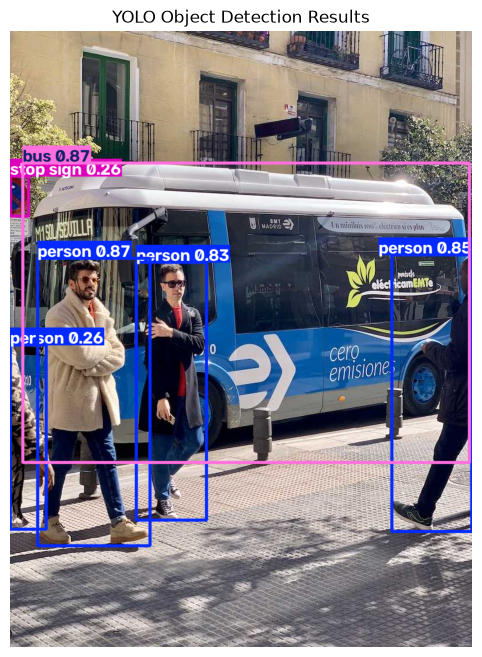

Saved as detection_result.jpg


In [9]:
# Method 2: Plot with matplotlib
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np
# Get the annotated image
annotated_img = results[0].plot()  # Returns numpy array with boxes drawn
# Convert BGR (OpenCV) to RGB (Matplotlib)
annotated_img_rgb = cv2.cvtColor(annotated_img, cv2.COLOR_BGR2RGB)
# Display
plt.figure(figsize=(10, 8))
plt.imshow(annotated_img_rgb)
plt.axis('off')
plt.title("YOLO Object Detection Results")
plt.show()
# Save results
cv2.imwrite('detection_result.jpg', annotated_img)
print("Saved as detection_result.jpg")

In [23]:
# Test on multiple images
image_urls = (
    'https://ultralytics.com/images/bus.jpg',
    'https://ultralytics.com/images/zidane.jpg', 'detection_result.jpg'
    )
for url in image_urls:
    results = model(url)
    img = results[0].plot()
    print(f"{url.split('/')[-1]}: {len(results[0].boxes)} objects detected")


Found https://ultralytics.com/images/bus.jpg locally at bus.jpg
image 1/1 c:\Users\User\OneDrive\Documents\UNIKL RELATED\Course Subjects\SEM 6 Subjects\Principle of Artificial Intelligence\lab 10\bus.jpg: 640x480 4 persons, 1 bus, 1 stop sign, 32.9ms
Speed: 2.2ms preprocess, 32.9ms inference, 0.8ms postprocess per image at shape (1, 3, 640, 480)
bus.jpg: 6 objects detected

Found https://ultralytics.com/images/zidane.jpg locally at zidane.jpg
image 1/1 c:\Users\User\OneDrive\Documents\UNIKL RELATED\Course Subjects\SEM 6 Subjects\Principle of Artificial Intelligence\lab 10\zidane.jpg: 384x640 2 persons, 1 tie, 32.0ms
Speed: 1.4ms preprocess, 32.0ms inference, 0.8ms postprocess per image at shape (1, 3, 384, 640)
zidane.jpg: 3 objects detected

image 1/1 c:\Users\User\OneDrive\Documents\UNIKL RELATED\Course Subjects\SEM 6 Subjects\Principle of Artificial Intelligence\lab 10\detection_result.jpg: 640x480 3 persons, 1 bus, 34.8ms
Speed: 1.8ms preprocess, 34.8ms inference, 1.1ms postproces

## MODULE C


In [25]:
import cv2
from ultralytics import YOLO
# Load model
model = YOLO('yolov8n.pt')
# Open video file (or use 0 for webcam)
video_path = 'sample_video.mp4'  # You can download a sample video
cap = cv2.VideoCapture(video_path)  # or cv2.VideoCapture(0) for webcam
# Get video properties
fps = int(cap.get(cv2.CAP_PROP_FPS))
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
# Define output video writer
out = cv2.VideoWriter('output_video.mp4', 
                      cv2.VideoWriter_fourcc(*'mp4v'), 
                      fps, (width, height))
frame_count = 0
while cap.isOpened():
    ret, frame = cap.read()
    if not ret:
        break
        
    # Run YOLO on frame
    results = model(frame, verbose=False)
        
    # Annotate frame
    annotated_frame = results[0].plot()
    
     # Write frame
    out.write(annotated_frame)
        
    # Display (optional)
    if frame_count % 30 == 0:  # Show every 30th frame
        cv2.imshow('YOLO Detection', annotated_frame)
        if cv2.waitKey(1) & 0xFF == ord('q'):
            break
    frame_count += 1
cap.release()
out.release()
cv2.destroyAllWindows()
print(f"Processed {frame_count} frames. Output saved to 'output_video.mp4'")

Processed 185 frames. Output saved to 'output_video.mp4'


1. Research: Ask ChatGPT: "What are the challenges of running object detection on video compared to single images?

    Running object detection on continuous video introduces several physical and computational complexities that don't exist when analyzing a single, static image:

- Processing Speed: Video = ~30 frames per second. Requires high GPU power to process instantly. Single images = processed once, no time limit.

- Motion Blur: Fast movement creates blurry frames. Blurry pixels lower detection accuracy. Static images = typically sharp and focused.

- Flickering Boxes: Models evaluate every frame independently. Slight pixel changes cause detection boxes to blink on and off rapidly.

- Occlusion & Tracking: Objects temporarily hide behind obstacles. Detectors lack frame-to-frame memory; reappearing objects are falsely identified as brand-new entities unless extra tracking software is added.

In [27]:
import time
import pandas as pd
# Measure inference speed
model = YOLO('yolov8n.pt')
times = []
n_runs = 100
for i in range(n_runs):
    start = time.time()
    results = model('https://ultralytics.com/images/bus.jpg')
    end = time.time()
    times.append(end - start)
avg_time = sum(times) / n_runs
fps = 1 / avg_time
print(f"Average inference time: {avg_time*1000:.2f} ms")
print(f"Frames per second (FPS): {fps:.1f}")
# Compare models
variants = ['yolov8n.pt', 'yolov8s.pt', 'yolov8m.pt']
comparison = []
for variant in variants:
    try:
        model = YOLO(variant)
        start = time.time()
        results = model('https://ultralytics.com/images/bus.jpg')
        end = time.time()
        comparison.append({
            'Model': variant,
            'Inference Time (ms)': (end - start) * 1000,
            'FPS': 1 / (end - start)
        })
    except:
        print(f"Model {variant} not found. Skipping.")
df = pd.DataFrame(comparison)
print(df)


Found https://ultralytics.com/images/bus.jpg locally at bus.jpg
image 1/1 c:\Users\User\OneDrive\Documents\UNIKL RELATED\Course Subjects\SEM 6 Subjects\Principle of Artificial Intelligence\lab 10\bus.jpg: 640x480 4 persons, 1 bus, 1 stop sign, 35.3ms
Speed: 2.2ms preprocess, 35.3ms inference, 1.0ms postprocess per image at shape (1, 3, 640, 480)

Found https://ultralytics.com/images/bus.jpg locally at bus.jpg
image 1/1 c:\Users\User\OneDrive\Documents\UNIKL RELATED\Course Subjects\SEM 6 Subjects\Principle of Artificial Intelligence\lab 10\bus.jpg: 640x480 4 persons, 1 bus, 1 stop sign, 30.5ms
Speed: 2.0ms preprocess, 30.5ms inference, 1.1ms postprocess per image at shape (1, 3, 640, 480)

Found https://ultralytics.com/images/bus.jpg locally at bus.jpg
image 1/1 c:\Users\User\OneDrive\Documents\UNIKL RELATED\Course Subjects\SEM 6 Subjects\Principle of Artificial Intelligence\lab 10\bus.jpg: 640x480 4 persons, 1 bus, 1 stop sign, 33.3ms
Speed: 2.0ms preprocess, 33.3ms inference, 0.8ms p

Fill in:

| Model Variant | Inference Time (ms) | FPS | Source |
| --- | --- | --- | --- |
| **YOLOv8n** | 61.96 | 16.14 | Code output |
| **YOLOv8s** | 122.59 | 8.16 | Code output |
| **YOLOv8m** | 241.77 | 4.14 | Code output |

## MODULE D

1. Ask ChatGPT: "What is transfer learning in object detection? How do you fine-tune YOLO on a custom dataset?"

    Transfer learning is a machine learning technique where a model developed for a broad, generalized task (like recognizing common objects in massive datasets) is reused as the starting point for a second, specialized task.

    To fine-tune YOLO on a custom dataset, you start by loading a model loaded with pre-trained weights (e.g., yolov8n.pt). Instead of randomly initializing the neural network, you use these pre-existing weights and train the model further on your own custom annotated images (using a dataset configuration .yaml file). The model keeps its foundational understanding of shapes and edges but adjusts its final layers to recognize your specific custom objects.

2. Ask ChatGPT: "What is the COCO dataset? How many classes does it have?"

    COCO (Common Objects in Context) is a massive, industry-standard benchmark dataset designed for object detection, segmentation, and captioning tasks. The standard COCO detection dataset features exactly 80 distinct object categories. It contains over 200,000 labeled images featuring common items ranging from vehicles and animals to everyday household objects.

    


| Concept | Explanation | Source |
| --- | --- | --- |
| **Transfer Learning** | Reusing a model's pre-trained weights (learned from a massive dataset) as a foundational starting point for a new, specific detection task. | https://www.geeksforgeeks.org/ml-transfer-learning/ |
| **Fine-tuning** | The process of slightly adjusting and training a pre-trained model's weights on a smaller, custom dataset so it specializes in a new task. | https://www.geeksforgeeks.org/fine-tuning-in-deep-learning/ |
| **Dataset Format (YOLO)** | A structured configuration requiring images paired with `.txt` label files containing the class ID and normalized bounding box coordinates (`class x_center y_center width height`). | https://docs.ultralytics.com/datasets/detect/ |
| **COCO Dataset** | A large-scale object detection dataset featuring 80 distinct object categories used as the standard benchmark for training baseline models. | https://docs.ultralytics.com/datasets/detect/coco/ |




3. Ask ChatGPT: "How are YOLO annotation files formatted? What does each number represent?"


    YOLO uses a text-based annotation format where each image has a corresponding `.txt` file with the exact same name. Inside this text file, every single object detected in the image gets its own row of data. Each row contains five numbers separated by spaces: `class_id`, `x_center`, `y_center`, `width`, and `height`. To ensure the model can train on images of any pixel size, all bounding box coordinates (x, y, width, and height) are normalized, meaning their values are scaled to be fractions between 0.0 and 1.0 relative to the overall image dimensions.

| Field | Description | Range | Example | Source |
| --- | --- | --- | --- | --- |
| **class_id** | The integer index representing the specific category of the object being identified (e.g., 0 for person, 1 for car). | 0 to (Total Classes - 1) | 0 | https://docs.ultralytics.com/datasets/detect/ |
| **x_center** | The X coordinate (horizontal center) of the bounding box, normalized by dividing by the total image width. | 0.0 to 1.0 | 0.5 | https://docs.ultralytics.com/datasets/detect/ |
| **y_center** | The Y coordinate (vertical center) of the bounding box, normalized by dividing by the total image height. | 0.0 to 1.0 | 0.5 | https://docs.ultralytics.com/datasets/detect/ |
| **width** | The total width of the bounding box, normalized by dividing by the total image width. | 0.0 to 1.0 | 0.3 | https://docs.ultralytics.com/datasets/detect/ |
| **height** | The total height of the bounding box, normalized by dividing by the total image height. | 0.0 to 1.0 | 0.4 | https://docs.ultralytics.com/datasets/detect/ |

---

3. Research: Ask ChatGPT: "What are the minimum requirements to train YOLO on a custom dataset? How many images do you need?"


    To technically begin training a YOLO model, the absolute minimum requirement is a properly structured dataset folder containing a `.yaml` configuration file, at least one training image, at least one validation image, and their corresponding `.txt` label files.


However, to train a model that actually performs well in real-world scenarios, the official Ultralytics guidelines recommend:

* **Images per class:** A minimum of $\ge 1,500$ images per specific object class.
* **Instances per class:** A minimum of $\ge 10,000$ labeled instances (bounding boxes) per specific object class.
* **Background images:** Including roughly 0-10% background images (images with absolutely no objects and no `.txt` label file) to help the model learn to reduce False Positives.

**Source:** https://docs.ultralytics.com/yolov5/tutorials/tips-for-best-training-results/

## MODULE E

In [2]:
# After running detection, evaluate results
# This requires ground truth annotations (for validation)
# Simulated evaluation
def calculate_iou(box1, box2):
    """Calculate IoU between two bounding boxes"""
    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])
    
    intersection = max(0, x2 - x1) * max(0, y2 - y1)
    area1 = (box1[2] - box1[0]) * (box1[3] - box1[1])
    area2 = (box2[2] - box2[0]) * (box2[3] - box2[1])
    union = area1 + area2 - intersection
    
    return intersection / union if union > 0 else 0
# Example: two boxes
box_gt = [10, 10, 50, 50]      # Ground truth
box_pred = [15, 15, 55, 55]    # Prediction
iou = calculate_iou(box_gt, box_pred)
print(f"IoU: {iou:.2f}")
# IoU > 0.5 is typically considered a correct detection (True Positive)

IoU: 0.62


1. Research: Ask ChatGPT: "What IoU threshold is commonly used to determine True Positives in object detection?"

    An **IoU threshold of 0.50 (50%)** is the universal baseline standard used to determine True Positives in object detection.

* **Baseline Standard (IoU $\ge$ 0.50):** Established by benchmark evaluations such as the PASCAL VOC challenge, a predicted bounding box is counted as a **True Positive (TP)** if its overlap with the ground-truth bounding box is greater than or equal to 0.50. If the overlap falls below 0.50, the detection is classified as a **False Positive (FP)**.


* **Strict Evaluation Benchmark (COCO mAP@[0.50:0.95]):** Standard benchmark datasets like MS COCO calculate precision across multiple IoU thresholds starting from 0.50 up to 0.95 in increments of 0.05 to evaluate both coarse localization and pixel-tight boundary alignment.
* **Task E.1 Code Output Evaluation:**
* Ground Truth Box: `[10, 10, 50, 50]`

* Predicted Box: `[15, 15, 55, 55]`

* Calculated Output: **IoU = 0.62**

* **Classification:** Because $0.62 \ge 0.50$, the predicted bounding box in your lab code is officially classified as a **True Positive (TP)**.


**Sources:**

* https://cocodataset.org/#detection-eval
* https://www.geeksforgeeks.org/computer-vision/what-are-different-evaluation-metrics-used-to-evaluate-image-segmentation-models/


Found https://ultralytics.com/images/bus.jpg locally at bus.jpg
image 1/1 c:\Users\User\OneDrive\Documents\UNIKL RELATED\Course Subjects\SEM 6 Subjects\Principle of Artificial Intelligence\lab 10\bus.jpg: 640x480 4 persons, 1 bus, 1 stop sign, 49.7ms
Speed: 2.5ms preprocess, 49.7ms inference, 1.2ms postprocess per image at shape (1, 3, 640, 480)


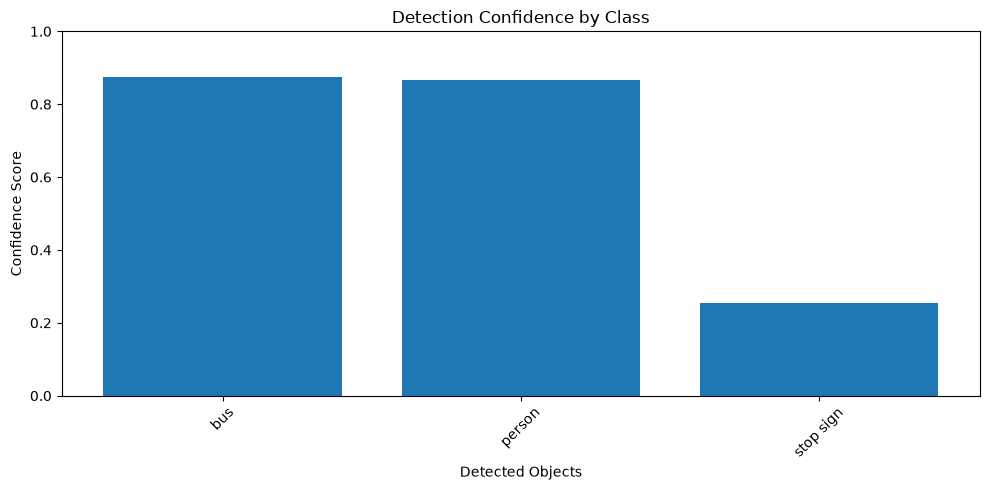

       Class  Confidence
0        bus    0.873448
1     person    0.865691
2     person    0.852835
3     person    0.825225
4     person    0.261112
5  stop sign    0.255069


In [6]:
from PIL import Image
import matplotlib.pyplot as plt
from ultralytics import YOLO

# Load the model so this analysis cell can run independently
model = YOLO('yolov8n.pt')

# Analyze detection confidence distribution
results = model('https://ultralytics.com/images/bus.jpg')
boxes = results[0].boxes
confidences = [box.conf[0].item() for box in boxes]
classes = [model.names[int(box.cls[0].item())] for box in boxes]
# Plot confidence distribution
plt.figure(figsize=(10, 5))
plt.bar(classes, confidences)
plt.ylim(0, 1)
plt.xlabel('Detected Objects')
plt.ylabel('Confidence Score')
plt.title('Detection Confidence by Class')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
# Create summary table
import pandas as pd
summary_df = pd.DataFrame({
    'Class': classes,
    'Confidence': confidences
})
print(summary_df)

Fill in:

### Task E.2 - Analysis of Detection Results

| Question | Answer | Source |
| --- | --- | --- |
| **Which object was detected with highest confidence?** | The `bus` with a confidence score of 0.87 (87.3%).| Code output |
| **Which object was detected with lowest confidence?** | The `stop sign` with a confidence score of 0.26 (25.5%).| Code output |
| **What was the average confidence score?** | The average confidence score across all six detections is ~0.66 (65.6%).| Code output |